# PDFT Calculation for HeH$^+$

In [1]:
import numpy as np
from pyscf import dft, scf
from f4b import pdft, fgto
from pyscf.dft import numint
import matplotlib.pyplot as plt

# function to get density in grid given density matrix and basis functions
def D2n(D, *phis):
    ngrid = len(phis)
    n = 0.
    for phi in phis:
        n += np.einsum("pu,pv,uv->p", phi, phi, D, optimize=True)
    n /= ngrid
    return n

---
## Set up fragments and do reference calculation

In [2]:
# define geometry
sep = 1.458869

mol = fgto.M(atom=f"""
    He {-0.5*sep} 0 0
    H {0.5*sep} 0 0
""", unit='bohr', basis='cc-pvdz', charge=1, spin=0,
    fragments={0: [0], 1: [1]},  # atom indices (1-based) of each fragment
    fcharge={0: 1},              # fragment 0 is He+ (one electron less); H stays neutral
    ensembles={"spin": [0, 1]})  # spin ensemble on both doublets (the notebook's (0.5, 0.5))

my_dft = dft.RKS(mol.mol)        # or dft.UKS for open shells
my_dft.xc = 'PBE'
my_dft.grids.level = 6           # same grid level as f4b, to compare energies cleanly
my_dft.kernel()                  # ks.e_tot, ks.make_rdm1()
Eref, Dref = my_dft.e_tot, my_dft.make_rdm1()
print(f"{Eref = :.8f}")

# Build an integration grid for the molecule.
grids = dft.gen_grid.Grids(mol.mol) # same for same basis with same number of atoms (ghost)
grids.level = 7
grids.build()
coords = grids.coords # [npoints, 3]
w = grids.weights # weights for integration
phi = dft.numint.eval_ao(mol.mol, coords, deriv=0) # AO basis functions on the grid
nref = D2n(Dref, phi)

Eref = -2.95909076


---
## Do PDFT Calculations

### Inversion Method

In [3]:
mf1 = pdft.RKS(mol, method='inversion', maxiter=20)
mf1.kernel()
E_mf1, Df_mf1 = mf1.e_tot, mf1.make_rdm1()
nf_mf1 = D2n(Df_mf1[0]+Df_mf1[1], phi)

dE_mf1 = abs(Eref-E_mf1)
L1_mf1 = np.sum(np.abs(nf_mf1-nref)*w)
Nf_mf1 = np.sum(nf_mf1*w)
print(f"Energy difference (Ha): {dE_mf1:.3e}, Density error: {L1_mf1:.3e}")

P-DFT method=inversion xc=PBE fxc=PBE nao=10 grid=62360
  it    1  Ef =    -2.4874032639  dEf =         nan  |dVp| = 1.323e+00
  it    2  Ef =    -2.4342541406  dEf =   5.315e-02  |dVp| = 1.038e+00
  it    3  Ef =    -2.3603059635  dEf =   7.395e-02  |dVp| = 8.223e-01
  it    4  Ef =    -2.2999594149  dEf =   6.035e-02  |dVp| = 6.727e-01
  it    5  Ef =    -2.2529400390  dEf =   4.702e-02  |dVp| = 5.665e-01
  it    6  Ef =    -2.2158804007  dEf =   3.706e-02  |dVp| = 4.876e-01
  it    7  Ef =    -2.1862434873  dEf =   2.964e-02  |dVp| = 4.275e-01
  it    8  Ef =    -2.1622952859  dEf =   2.395e-02  |dVp| = 3.808e-01
  it    9  Ef =    -2.1428090473  dEf =   1.949e-02  |dVp| = 3.444e-01
  it   10  Ef =    -2.1268711932  dEf =   1.594e-02  |dVp| = 3.156e-01
  it   11  Ef =    -2.1137812096  dEf =   1.309e-02  |dVp| = 2.926e-01
  it   12  Ef =    -2.1029870480  dEf =   1.079e-02  |dVp| = 2.742e-01
  it   13  Ef =    -2.0940490358  dEf =   8.938e-03  |dVp| = 2.592e-01
  it   14  Ef =    -2

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 20 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


### Functional Method

In [4]:
mf2 = pdft.RKS(mol, method='functional-T', maxiter=20)
mf2.kernel()
E_mf2, Df_mf2 = mf2.e_tot, mf2.make_rdm1()
nf_mf2 = D2n(Df_mf2[0]+Df_mf2[1], phi)

dE_mf2 = abs(Eref-E_mf2)
L1_mf2 = np.sum(np.abs(nf_mf2-nref)*w)
Nf_mf2 = np.sum(nf_mf2*w)
print(f"Energy difference (Ha): {dE_mf2:.3e}, Density error: {L1_mf2:.3e}")

P-DFT method=functional xc=PBE fxc=PBE nao=10 grid=62360
  it    1  Ef =    -2.4874032639  dEf =         nan  |dVp| = 1.422e+00
  it    2  Ef =    -2.4163463829  dEf =   7.106e-02  |dVp| = 1.041e+00
  it    3  Ef =    -2.3437504463  dEf =   7.260e-02  |dVp| = 7.399e-01
  it    4  Ef =    -2.2928866183  dEf =   5.086e-02  |dVp| = 6.808e-01
  it    5  Ef =    -2.2531492326  dEf =   3.974e-02  |dVp| = 8.394e-01
  it    6  Ef =    -2.2201385289  dEf =   3.301e-02  |dVp| = 9.812e-01
  it    7  Ef =    -2.0456608273  dEf =   1.745e-01  |dVp| = 2.034e+01


/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/fragment.py:138: UserWarning: fragment 1 member (1,0) SCF did not converge
  warnings.warn(f"fragment {frag.index} member ({m.na},{m.nb}) SCF did not converge")
/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:375: UserWarning: P-DFT iterations are diverging (it 7); stopping and using the best iterate
  warnings.warn(f"P-DFT iterations are diverging (it {it}); stopping and using the best iterate")


Energy difference (Ha): 3.499e-02, Density error: 3.748e-01


### Reference Method

In [5]:
mf3 = pdft.RKS(mol, method='reference', ref_dm=Dref, maxiter=30)
mf3.kernel()
E_mf3, Df_mf3 = mf3.e_tot, mf3.make_rdm1()
nf_mf3 = D2n(Df_mf3[0]+Df_mf3[1], phi)

dE_mf3 = abs(Eref-E_mf3)
L1_mf3 = np.sum(np.abs(nf_mf3-nref)*w)
Nf_mf3 = np.sum(nf_mf3*w)
print(f"Energy difference (Ha): {dE_mf3:.3e}, Density error: {L1_mf3:.3e}")

P-DFT method=reference xc=PBE fxc=PBE nao=10 grid=62360
  it    1  Ef =    -2.4874032639  dEf =         nan  |dVp| = 2.450e-01  L1 = 1.020e+00
  it    2  Ef =    -2.4654845952  dEf =   2.192e-02  |dVp| = 1.729e-01  L1 = 8.863e-01
  it    3  Ef =    -2.4341836605  dEf =   3.130e-02  |dVp| = 1.336e-01  L1 = 7.867e-01
  it    4  Ef =    -2.4058699010  dEf =   2.831e-02  |dVp| = 1.087e-01  L1 = 7.072e-01
  it    5  Ef =    -2.3816360758  dEf =   2.423e-02  |dVp| = 9.172e-02  L1 = 6.438e-01
  it    6  Ef =    -2.3610673334  dEf =   2.057e-02  |dVp| = 7.948e-02  L1 = 5.928e-01
  it    7  Ef =    -2.3435596804  dEf =   1.751e-02  |dVp| = 7.036e-02  L1 = 5.509e-01
  it    8  Ef =    -2.3285606820  dEf =   1.500e-02  |dVp| = 6.341e-02  L1 = 5.160e-01
  it    9  Ef =    -2.3156072767  dEf =   1.295e-02  |dVp| = 5.799e-02  L1 = 4.864e-01
  it   10  Ef =    -2.3043269439  dEf =   1.128e-02  |dVp| = 5.369e-02  L1 = 4.611e-01
  it   11  Ef =    -2.2944189874  dEf =   9.908e-03  |dVp| = 5.021e-02  L1

/home/ulises/anaconda3/envs/f4b/lib/python3.8/site-packages/f4b/pdft.py:389: UserWarning: P-DFT did not converge in 30 iterations; using the best iterate
  warnings.warn(f"P-DFT did not converge in {self.maxiter} iterations; using the best iterate")


---
## Plot densities and partition potential

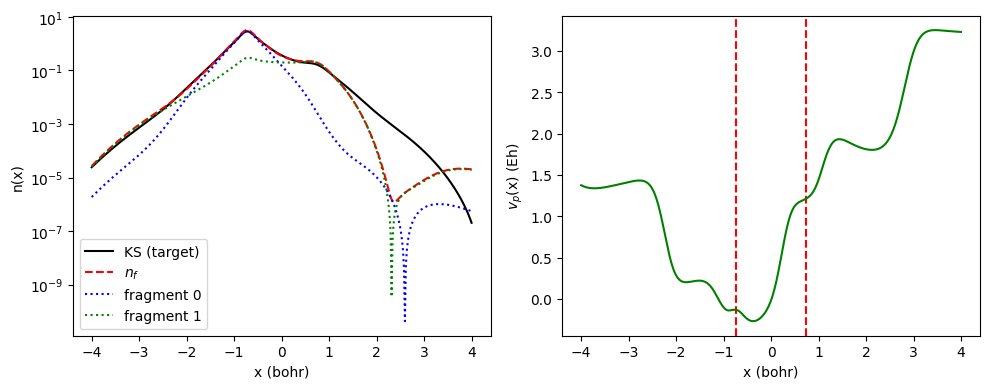

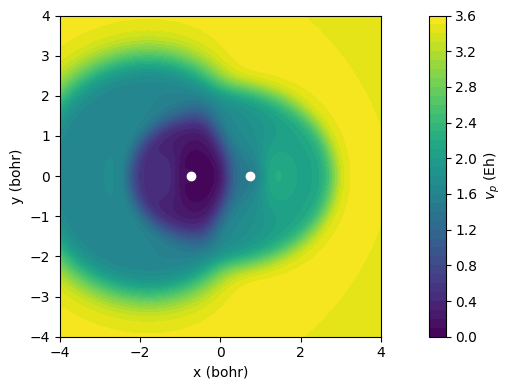

In [6]:
# # 1D plot along molecular axis
x = np.linspace(-4, 4, 400)
line = np.column_stack([x, np.zeros_like(x), np.zeros_like(x)])
n_f = mf1.eval_density(line)                    # promolecular density
n_0 = mf1.eval_density(line, frag=0)            # fragment densities
n_1 = mf1.eval_density(line, frag=1)
vp  = mf1.eval_Vp(line)
n_ks = numint.eval_rho(mol.mol, numint.eval_ao(mol.mol, line), Dref) # target (plain KS) density on the same points
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].semilogy(x, n_ks, 'k-', label='KS (target)')
ax[0].semilogy(x, n_f, 'r--', label='$n_f$')
ax[0].semilogy(x, n_0, 'b:', label='fragment 0')
ax[0].semilogy(x, n_1, 'g:', label='fragment 1')
for Ri in mol.mol.atom_coords(): ax[1].axvline(x=Ri[0], color='r', linestyle='dashed')
ax[0].set_xlabel('x (bohr)'); ax[0].set_ylabel('n(x)'); ax[0].legend()
ax[1].plot(x, vp - vp[len(x) // 2], 'g-')      # Vp is defined up to a constant: fix a reference point
ax[1].set_xlabel('x (bohr)'); ax[1].set_ylabel('$v_p$(x) (Eh)')
fig.tight_layout()
plt.show()

# 2D map of Vp in the xy plane (z = 0)
x = np.linspace(-4, 4, 160); yy = np.linspace(-4, 4, 160)
X, Y = np.meshgrid(x, yy)
pts = np.column_stack([X.ravel(), Y.ravel(), np.zeros(X.size)])
V = mf1.eval_Vp(pts).reshape(X.shape)
fig, ax = plt.subplots(figsize=(10, 4))
c = ax.contourf(X, Y, V - V.min(), 40, cmap='viridis'); fig.colorbar(c, label='$v_p$ (Eh)')
for Ri in mol.mol.atom_coords():  ax.plot(Ri[0], Ri[1], 'wo')
ax.set_xlabel('x (bohr)'); ax.set_ylabel('y (bohr)'); ax.set_aspect('equal')
fig.tight_layout()
plt.show()